# Pivot switching: the logistic equation

This example compares plain Carleman with pivot-switching Carleman on $\dot x=x(1-x)$, from
$x_0=0.1$ at truncation degree 3. Carleman diverges. PSC stays bounded, and its accuracy improves
the more closely the pivot follows $x$.

:::{seealso}
- [Vocabulary and symbols](../../docs/concepts.md) defines PSC, pivot and fold.
- [`psc_carleman`](../tutorials/04_basis/psc_carleman.ipynb) constructs `PSCarlemanBasis`, and
  derives and checks both generators: plain Carleman (the paper's Eq. 3) and PSC (its Eq. 16).
:::

The truncation degree is written $P$ for PSC and $K$ for plain Carleman, following the paper. Both
name the same knob, which the code calls `degree`.

| method | pivot |
|---|---|
| conventional Carleman | — |
| PSC, fixed | $s=1$, the attractor |
| PSC, switched | $s:0\to1$ at $t=1$ |

The analytic solution $x(t)=x_0e^t/(1-x_0+x_0e^t)$ is the reference.

This page rebuilds both generators and propagates them, reproducing Figs. 1(a) and 2(d) of
[arXiv:2411.16233](https://arxiv.org/abs/2411.16233).


<!-- figure: psc-fold (docs/make_figures.py) -->

> **What a fold is.** $u^{P+1}$ is above the degree, so PSC replaces it with its degree-$P$ Taylor
> polynomial about $s$:
>
> $$u^{4}\;\longmapsto\;-s^{4}+4s^{3}u-6s^{2}u^{2}+4s\,u^{3}\qquad(P=3)$$
>
> ![The PSC fold: the weights it leaves on each retained basis state](../figures/psc-fold.png)
>
> A gold box holds the weight left on the state above it. Only the top row applies here. The second
> row needs a cubic reaction, as in [`psc_fig4_phase_field`](psc_fig4_phase_field.ipynb).
>
> At $s=0$ every weight is zero. The term is then dropped, which is plain Carleman.


<!-- figure: psc-elements (docs/make_figures.py) -->

> **What the fold costs, and what it does not.**
>
> $$L\,x^{3}=3x^{2}\bigl(x-x^{2}\bigr)=3x^{3}-3x^{4}$$
>
> $$\langle x^{3}\rvert L\lvert x^{3}\rangle=3-12s,\qquad \langle x^{2}\rvert L\lvert x^{3}\rangle=18s^{2},\qquad \langle x\rvert L\lvert x^{3}\rangle=-12s^{3},\qquad \langle 1\rvert L\lvert x^{3}\rangle=3s^{4}$$
>
> Carleman gives the first and zero for the other three.
>
> ![Which elements the fold turns on, and which elements repeat across sites](../figures/psc-elements.png)
>
> | | |
> |---|---|
> | **nonzero** | the fold turns 1 element into 4, one for every retained bra |
> | **same value** | the weights carry no site index, so $N$ sites share one element call |
>
> So PSC costs a denser row, not more element calls.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from collections.abc import Sequence
from scipy.sparse import csc_matrix
from scipy.sparse.linalg import expm_multiply

from lin_ode.basis import CarlemanBasis, PSCarlemanBasis, TruncatedBasisSet
from lin_ode.operators import Koopman
from lin_ode import OperatorMatrix, OrdinaryDifferentialSystem
from lin_ode.vector import Vector

DEGREE, X0, T_END, SWITCH, FRAMES = 3, 0.1, 5.0, 1.0, 501
s = sp.Symbol("s")  # the pivot, substituted once the matrix is built

x, i = sp.IndexedBase("x"), sp.Idx("i", (0, 0))
logistic = OrdinaryDifferentialSystem.from_sympy(x[i] * (1 - x[i]), x, (i,))

carleman_basis = CarlemanBasis(1, DEGREE)
psc_basis = PSCarlemanBasis(1, DEGREE, pivot=s)


def state_matrix(basis: TruncatedBasisSet) -> sp.Matrix:
    """A in dy/dt = A y, for the logistic equation projected onto `basis`."""
    labels = [basis.structured_idx_of_flat_index(k) for k in range(len(basis))]
    block = OperatorMatrix(basis, Koopman().create_operator(logistic))[labels, labels]
    return sp.simplify(block.T)


A_carleman = state_matrix(carleman_basis)
A_psc = state_matrix(psc_basis)
display(A_carleman, A_psc)

Matrix([
[0, 0,  0,  0],
[0, 1, -1,  0],
[0, 0,  2, -2],
[0, 0,  0,  3]])

Matrix([
[     0,        0,       0,        0],
[     0,        1,      -1,        0],
[     0,        0,       2,       -2],
[3*s**4, -12*s**3, 18*s**2, 3 - 12*s]])

The system is linear, so $\boldsymbol y(t)=e^{At}\boldsymbol y(0)$ is exact. Nothing below can be
blamed on an integrator, and what is left is the truncation error.

PSC differs from plain Carleman in the **last row only**. That row is the folded $x^4$, and it is
the only place the pivot appears.

The pivot lives in the matrix, not the states: $y_k=x^k$ regardless of $s$. So a switch swaps the
propagator and reuses the state vector unchanged.

At $s=0$ PSC *is* conventional Carleman, because the Taylor polynomial of $x^4$ about $0$ is zero.

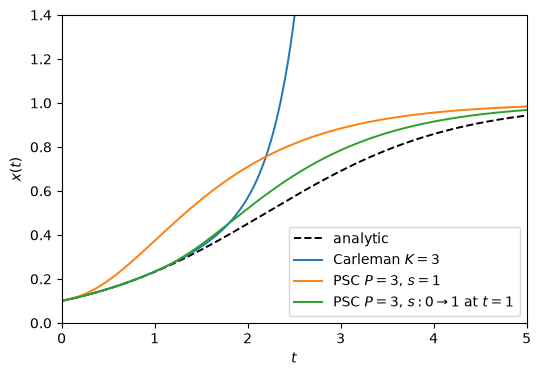

analytic                       x(5) =     0.9428   max|error| =          0
Carleman $K=3$                 x(5) =       3021   max|error| =       3020
PSC $P=3$, $s=1$               x(5) =     0.9837   max|error| =     0.2589
PSC $P=3$, $s:0\to1$ at $t=1$  x(5) =      0.968   max|error| =     0.0979


In [2]:
def numeric(A: sp.Matrix, pivot: float | None = None) -> csc_matrix:
    """`A` with the pivot substituted, as a sparse float matrix."""
    return csc_matrix(np.array(A.subs({s: pivot} if pivot is not None else {}), dtype=float))


def evolve(
    segments: Sequence[tuple[float, csc_matrix]],
    initial: np.ndarray,
    frames: int = FRAMES,
) -> tuple[np.ndarray, np.ndarray]:
    """(times, y(t)) for dy/dt = A y, exponentiating each `(t_to, A)` segment in turn."""
    vec, t_from = initial, 0.0
    times, blocks = [np.zeros(1)], [initial[None, :]]
    for t_to, matrix in segments:
        num = 1 + round((t_to - t_from) / T_END * (frames - 1))
        block = expm_multiply(matrix, vec, start=0, stop=t_to - t_from, num=num, endpoint=True)
        times.append(np.linspace(t_from, t_to, num)[1:])  # [1:]: t_from is already in
        blocks.append(block[1:])
        vec, t_from = block[-1], t_to
    return np.concatenate(times), np.concatenate(blocks)


initial_vector = X0 ** np.arange(DEGREE + 1, dtype=float)  # y_k(0) = x0**k

# full trajectories kept, not just y_1 — the observable further down rides on all of y
times, y_carleman = evolve([(T_END, numeric(A_carleman))], initial_vector)
_, y_psc_fixed = evolve([(T_END, numeric(A_psc, 1.0))], initial_vector)
_, y_psc_switched = evolve(
    [(SWITCH, numeric(A_psc, 0.0)), (T_END, numeric(A_psc, 1.0))], initial_vector
)

carleman, psc_fixed, psc_switched = (
    trajectory[:, 1] for trajectory in (y_carleman, y_psc_fixed, y_psc_switched)
)  # x = y_1

analytic = X0 * np.exp(times) / (1 - X0 + X0 * np.exp(times))

solutions = (
    ("analytic", analytic),
    ("Carleman $K=3$", carleman),
    ("PSC $P=3$, $s=1$", psc_fixed),
    ("PSC $P=3$, $s:0\\to1$ at $t=1$", psc_switched),
)

fig, ax = plt.subplots(figsize=(6, 4))
for label, curve in solutions:
    ax.plot(times, curve, "k--" if label == "analytic" else "-", lw=1.4, label=label)
ax.set(xlabel="$t$", ylabel="$x(t)$", ylim=(0, 1.4), xlim=(0, T_END))
ax.legend()
plt.show()

for label, curve in solutions:
    print(f"{label:30s} x(5) = {curve[-1]:10.4g}   "
          f"max|error| = {np.abs(curve - analytic).max():10.4g}")

Carleman departs from the analytic solution near $t\approx2.4$ and then diverges (Fig. 1a). Both PSC
runs stay bounded (Fig. 2d).

Neither PSC curve sits *on* the analytic curve, and the fixed pivot is the worse of the two. The fold
remainder is $O\bigl((x-s)^{P+1}\bigr)$, so it grows with the distance from the pivot.

| | why |
|---|---|
| fixed at $s=1$ | $x_0=0.1$ is far from the pivot, so the discarded remainder is large early |
| switched at $t=1$ | by then $x$ is near $1$, so the remainder is small |

## Reading out an observable above the truncation

An observable is a row vector against the same trajectory,
$g(x(t))=\vec c^{\;\mathsf T}\boldsymbol y(t)$, and `Vector` returns $\vec c$.

Take $g=x^4$, one degree **above** the truncation. $x^4$ is not a state of the system, so the
coefficients are the only way to compute it:

$$x^4 \;\approx\; \sum_{m=0}^{3}\binom{4}{m}s^{4-m}(x-s)^m
\;\xrightarrow{\;s=1\;}\; 4x^3-6x^2+4x-1,
\qquad \text{Carleman: } \vec c = \boldsymbol 0$$

Two things go wrong independently, and the plot separates them:

| error source | what it is |
|---|---|
| trajectory drift | the lifted state $y_1$ has left the true $x$ |
| fold remainder | the Taylor tail discarded when $x^4$ was folded onto the basis |

The four curves plotted below:

| legend entry | what it is |
|---|---|
| analytic $x^4$ | the true answer |
| $y_1(t)^4$ | the model's own $x$, raised classically. A linear read-out only ever sees $\vec c^{\;\mathsf T}\boldsymbol y$, so the lifted system cannot produce this curve itself |
| $\vec c\cdot\boldsymbol y$, PSC $s=1$ | the read-out under test |
| $\vec c\cdot\boldsymbol y$, Carleman | flat zero, because $\vec c=\boldsymbol 0$ |

Scoring the read-out against $y_1^4$ rather than against the analytic curve isolates the remainder
from the drift. At $t=0$ it is pure remainder, since $y_k=y_1^k$ exactly there.

c for x^4:   Carleman [0. 0. 0. 0.]   PSC s=1 [-1.  4. -6.  4.]


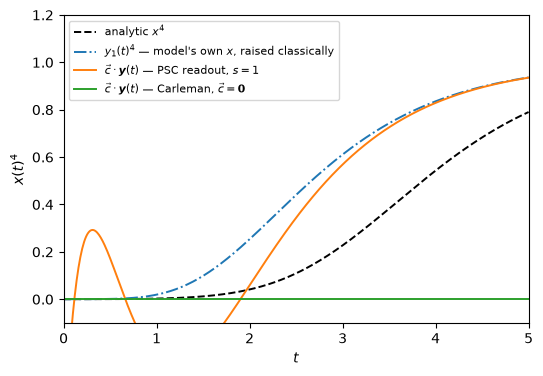

t=0   readout |c.y - y_1^4| =     0.656   trajectory |y_1^4 - analytic^4| =         0
t=2   readout |c.y - y_1^4| =     0.195   trajectory |y_1^4 - analytic^4| =     0.212
t=5   readout |c.y - y_1^4| =  0.000969   trajectory |y_1^4 - analytic^4| =     0.146


In [3]:
def observable(expr: sp.Expr, basis: TruncatedBasisSet, pivot: float | None = None) -> np.ndarray:
    """Row vector c with c @ y(t) = <expr>(t): `expr` projected onto `basis`."""
    entries = Vector(expr, basis, x)
    coeffs = [entries[basis.structured_idx_of_flat_index(k)] for k in range(len(basis))]
    free = {sym for c in coeffs for sym in c.free_symbols} - ({s} if pivot is not None else set())
    if free:
        raise ValueError(f"coefficients still carry {free}; pass the pivot this basis was built with")
    return np.array([float(c.subs({s: pivot} if pivot is not None else {})) for c in coeffs])


read_x4_carleman = observable(x[0] ** 4, carleman_basis)
read_x4_psc = observable(x[0] ** 4, psc_basis, pivot=1.0)
print(f"c for x^4:   Carleman {read_x4_carleman}   PSC s=1 {read_x4_psc}")

# matplotlib mathtext needs \boldsymbol{y}, not \boldsymbol y — the bare form is a ValueError
psc_readout = y_psc_fixed @ read_x4_psc
curves = (
    ("analytic $x^4$", analytic**4, "k--"),
    ("$y_1(t)^4$ — model's own $x$, raised classically", psc_fixed**4, "-."),
    ("$\\vec c\\cdot\\boldsymbol{y}(t)$ — PSC readout, $s=1$", psc_readout, "-"),
    ("$\\vec c\\cdot\\boldsymbol{y}(t)$ — Carleman, $\\vec c=\\boldsymbol{0}$", y_carleman @ read_x4_carleman, "-"),
)

fig, ax = plt.subplots(figsize=(6, 4))
for label, curve, style in curves:
    ax.plot(times, curve, style, lw=1.4, label=label)
ax.set(xlabel="$t$", ylabel="$x(t)^4$", ylim=(-0.1, 1.2), xlim=(0, T_END))
ax.legend(fontsize=8, loc="upper left")
plt.show()

# both scored against y_1^4, so the readout's error is not charged the trajectory's
for t_at in (0.0, 2.0, 5.0):
    j = int(np.abs(times - t_at).argmin())
    print(f"t={t_at:.0f}   readout |c.y - y_1^4| = {abs(psc_readout[j] - psc_fixed[j] ** 4):9.3g}"
          f"   trajectory |y_1^4 - analytic^4| = {abs(psc_fixed[j] ** 4 - analytic[j] ** 4):9.3g}")

## PSC error over time

The plots above stop at $t=5$, the window of the paper's Fig. 2(d), and that is where PSC becomes
the more accurate method. Two facts pin the error to a transient:

- **$t=0$:** $\boldsymbol y(0)$ is exact ($y_k=x_0^k$), so the error starts at zero.
- **$t\to\infty$:** $A(s{=}1)$ has the fixed point $y_0=y_1=y_2=y_3$, and $y_0\equiv1$, so
  $y_1\to1$. The linear system inherits the logistic attractor *exactly*, not approximately.

In between, $x$ is farthest from the pivot and the $O\bigl((x-s)^{P+1}\bigr)$ remainder is largest.
Extending to $t=12$ shows the peak, then the decay.


fixed point of A(s=1): {y0: y3, y1: y3, y2: y3}


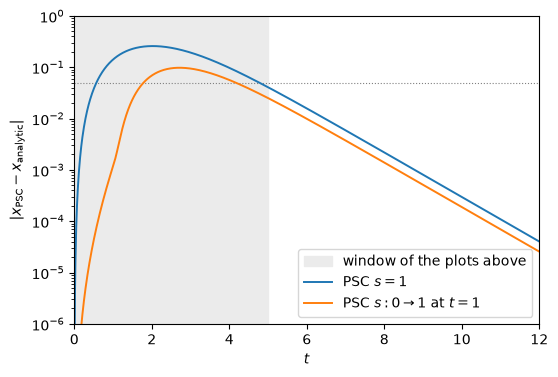

PSC $s=1$                max 0.2589 at t= 2.02   |err|<0.05 from t= 4.78 on   err(12) = 4.03e-05
PSC $s:0\to1$ at $t=1$   max 0.0979 at t= 2.72   |err|<0.05 from t= 4.18 on   err(12) = 2.56e-05


In [4]:
T_LONG = 12.0

print("fixed point of A(s=1):", sp.solve(A_psc.subs({s: 1}) * sp.Matrix(sp.symbols("y0:4")), sp.symbols("y0:4")))

times_long, y_long_fixed = evolve([(T_LONG, numeric(A_psc, 1.0))], initial_vector)
t_switched, y_long_switched = evolve(
    [(SWITCH, numeric(A_psc, 0.0)), (T_LONG, numeric(A_psc, 1.0))], initial_vector
)
assert np.allclose(times_long, t_switched)  # both runs land on the same grid, so one x-axis serves

analytic_long = X0 * np.exp(times_long) / (1 - X0 + X0 * np.exp(times_long))
errors = (
    ("PSC $s=1$", np.abs(y_long_fixed[:, 1] - analytic_long)),
    ("PSC $s:0\\to1$ at $t=1$", np.abs(y_long_switched[:, 1] - analytic_long)),
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.axvspan(0, T_END, color="0.92", zorder=0, label="window of the plots above")
ax.axhline(0.05, color="0.5", lw=0.8, ls=":")
for label, err in errors:
    ax.semilogy(times_long, err, lw=1.4, label=label)
ax.set(xlabel="$t$", ylabel="$|x_\\mathrm{PSC}-x_\\mathrm{analytic}|$", xlim=(0, T_LONG), ylim=(1e-6, 1))
ax.legend()
plt.show()

for label, err in errors:
    peak = int(err.argmax())
    back = times_long[int(np.where(err >= 0.05)[0][-1]) + 1]  # last exit from the 5% band
    print(f"{label:24s} max {err[peak]:.4f} at t={times_long[peak]:5.2f}   "
          f"|err|<0.05 from t={back:5.2f} on   err(12) = {err[-1]:.2e}")

## Moving the pivot every step

PSC is named for moving the pivot whenever the state leaves its neighbourhood. Here it moves on a
fixed schedule: $s\mapsto x(t)$ every $\Delta t$, one propagator per segment.

That makes $\Delta t$ an accuracy knob, and $x^4$ measures it from above the truncation.

dt=1.0     5 switches   max|x - exact| = 1.20e-02   max|<x^4> - exact^4| = 1.62e-02
dt=0.5    10 switches   max|x - exact| = 7.38e-04   max|<x^4> - exact^4| = 1.03e-03
dt=0.25   20 switches   max|x - exact| = 4.50e-05   max|<x^4> - exact^4| = 6.30e-05
dt=0.1    50 switches   max|x - exact| = 1.12e-06   max|<x^4> - exact^4| = 1.57e-06


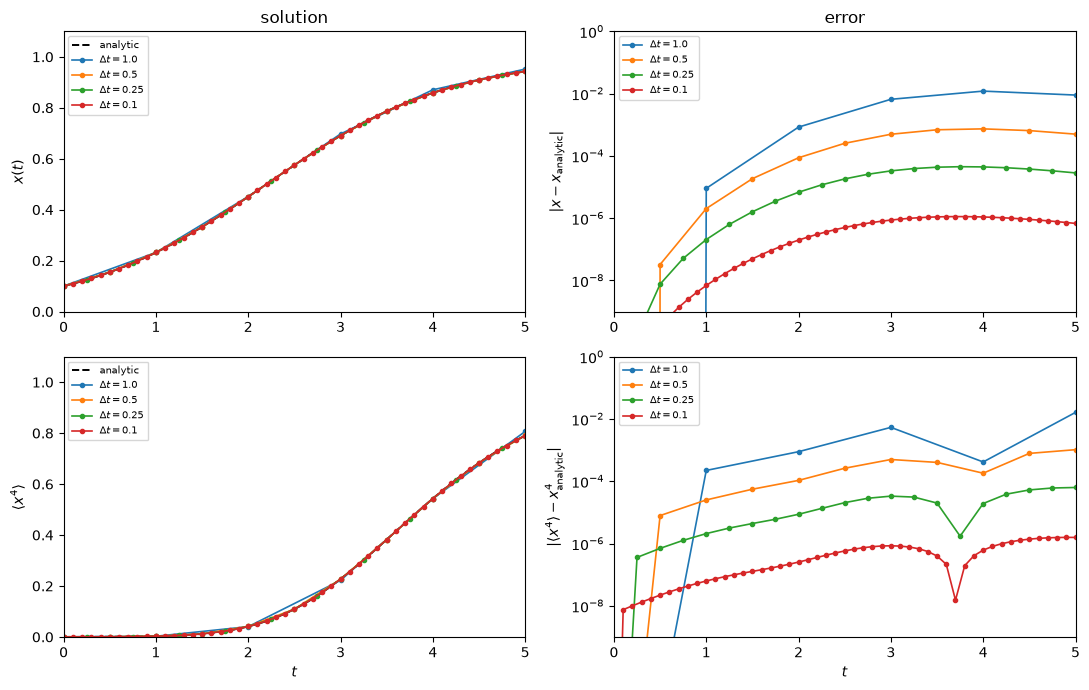

In [5]:
from scipy.linalg import expm

labels = [psc_basis.structured_idx_of_flat_index(k) for k in range(len(psc_basis))]
A_of = sp.lambdify(s, A_psc)                                                 # A(s)
c_of = sp.lambdify(s, [Vector(x[0] ** 4, psc_basis, x)[k] for k in labels])  # c(s) for <x^4>


def track(dt: float):
    """Evolve dy/dt = A(s)y, re-pivoting on the current x every `dt`. Returns t, x, <x^4>."""
    y = initial_vector
    out = [(0.0, y[1], np.array(c_of(y[1])) @ y)]
    for n in range(round(T_END / dt)):
        pivot = y[1]                                                         # s <- current x
        y = expm(np.asarray(A_of(pivot), dtype=float) * dt) @ y
        out.append(((n + 1) * dt, y[1], np.array(c_of(pivot)) @ y))
    return (np.array(col) for col in zip(*out))


fig, axes = plt.subplots(2, 2, figsize=(11, 7))
(ax_x, ax_x_err), (ax_x4, ax_x4_err) = axes
ax_x.plot(times, analytic, "k--", lw=1.4, label="analytic")  # dense reference from above
ax_x4.plot(times, analytic**4, "k--", lw=1.4, label="analytic")

for dt in (1.0, 0.5, 0.25, 0.1):
    t, x_psc, x4_psc = track(dt)
    exact = X0 * np.exp(t) / (1 - X0 + X0 * np.exp(t))
    label = f"$\\Delta t={dt}$"
    ax_x.plot(t, x_psc, "o-", ms=3, lw=1.2, label=label)
    ax_x_err.semilogy(t, np.abs(x_psc - exact), "o-", ms=3, lw=1.2, label=label)
    ax_x4.plot(t, x4_psc, "o-", ms=3, lw=1.2, label=label)
    ax_x4_err.semilogy(t, np.abs(x4_psc - exact**4), "o-", ms=3, lw=1.2, label=label)
    print(f"dt={dt:<5} {round(T_END / dt):3d} switches   "
          f"max|x - exact| = {np.abs(x_psc - exact).max():.2e}   "
          f"max|<x^4> - exact^4| = {np.abs(x4_psc - exact**4).max():.2e}")

ax_x.set(ylabel="$x(t)$", title="solution", ylim=(0, 1.1))
ax_x_err.set(ylabel="$|x-x_\\mathrm{analytic}|$", title="error", ylim=(1e-9, 1))
ax_x4.set(xlabel="$t$", ylabel="$\\langle x^4\\rangle$", ylim=(0, 1.1))
ax_x4_err.set(xlabel="$t$", ylabel="$|\\langle x^4\\rangle-x_\\mathrm{analytic}^4|$", ylim=(1e-9, 1))
for ax in axes.ravel():
    ax.set_xlim(0, T_END)
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Error falls by $\approx16$ each time $\Delta t$ halves, which is **fourth order**,
$O(\Delta t^{P+1})$.

Between switches $x-s=O(\Delta t)$, and the discarded remainder is $O((x-s)^{P+1})$.

The $x^4$ read-out converges at the same rate as the state itself, so an observable *above* the
truncation costs no accuracy, as long as the pivot keeps tracking $x$.

---

[← Pivot switching: phase field](psc_fig4_phase_field.ipynb) · [Notebook index](../README.md) · [Koopman–von Neumann oscillator →](kvn_heisenberg.ipynb)